# Creation of toy datasets using Scikit-learn

## Using *make_*

In [2]:
from sklearn.datasets import make_classification, make_regression, make_blobs, make_moons

In [3]:
# X_clf: A 2D NumPy array of shape (100, 4) containing the input features (independent variables).
# y_clf: A 1D NumPy array of shape (100,) containing the target labels (0 or 1 by default).

X_clf, y_clf = make_classification(
    n_samples=100,      # Total number of data points (rows) to generate.
    n_features=3,       # Total number of features (columns). It equals: informative + redundant + repeated + random noise.
    n_informative=3,    # Number of features that actually carry useful signal to separate the classes.
    n_redundant=0,      # Number of features generated as random linear combinations of the informative features (set to 0 here, so no multicollinearity).
                        # Note: Because n_features=3 and informative+redundant=2, the remaining 1 feature is filled with pure random noise.
    random_state=42,     # Seed for the random number generator. Ensures you get the exact same dataset every time you run the code.
    n_classes=3,            # Configures y_clf to have values: 0, 1, or 2
    n_clusters_per_class=1,
    class_sep=1.1,
)

In [4]:
print("X_clf")
print(X_clf[:5,:])
print("shape", X_clf.shape)
print()

print("y_clf")
print(y_clf[:5])
print("shape", y_clf.shape)

X_clf
[[-0.73653144  0.53905714 -1.38721733]
 [-0.45714951  0.84837919  1.2344456 ]
 [-2.21161929 -0.58086296 -0.41786597]
 [-0.3637195  -1.26719686  1.00058994]
 [ 0.41448008 -0.47386752  1.10076847]]
shape (100, 3)

y_clf
[2 1 0 0 1]
shape (100,)


In [5]:
import matplotlib.pyplot as plt

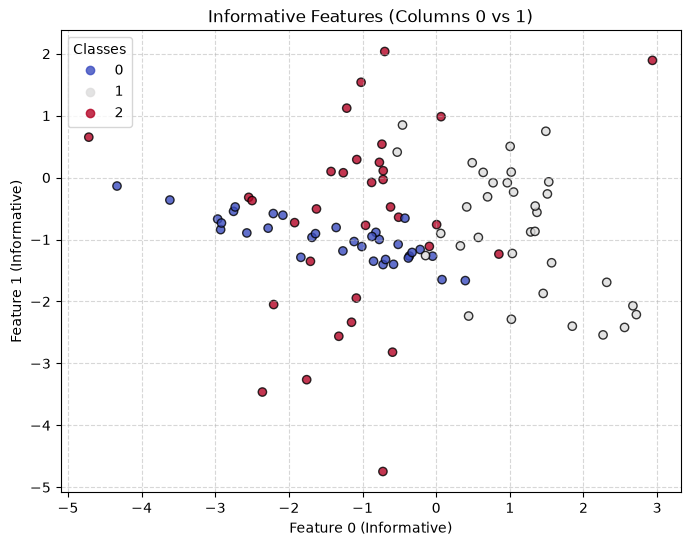

In [6]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_clf[:, 0],          # First informative feature (X-axis)
    X_clf[:, 1],          # Second informative feature (Y-axis)
    c=y_clf,              # Color points by their class label (0 or 1)
    cmap='coolwarm',      # Color scheme (blue vs. red)
    edgecolors='k',       # Black border around dots for readability
    alpha=0.8
)

plt.title("Informative Features (Columns 0 vs 1)")
plt.xlabel("Feature 0 (Informative)")
plt.ylabel("Feature 1 (Informative)")
plt.legend(*scatter.legend_elements(), title="Classes")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

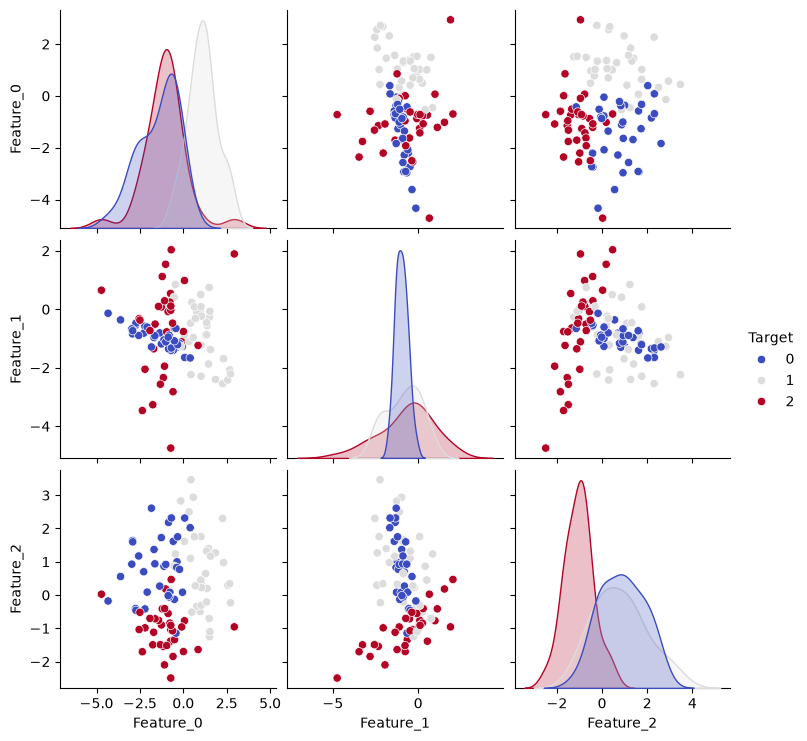

In [7]:
import pandas as pd
import seaborn as sns

# Convert to DataFrame for easy plotting
df = pd.DataFrame(X_clf, columns=[f"Feature_{i}" for i in range(3)])
df["Target"] = y_clf

# Creates a 4x4 grid comparing every feature pair
sns.pairplot(df, hue="Target", palette="coolwarm", diag_kind="kde")
plt.show()

In [8]:
df.to_csv("./dbs/classification_toy_dataset.csv", index=False)

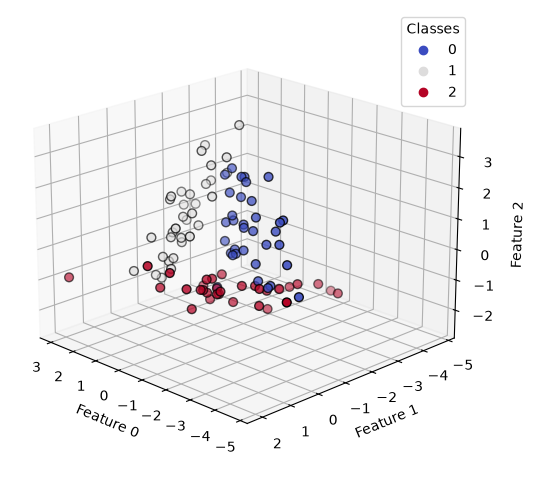

In [9]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(
    X_clf[:, 0], X_clf[:, 1], X_clf[:, 2],
    c=y_clf, cmap='coolwarm', edgecolors='k', s=40
)
ax.set_xlabel("Feature 0")
ax.set_ylabel("Feature 1")
ax.set_zlabel("Feature 2")

ax.view_init(elev=20, azim=135)  # elev: up/down angle, azim: left/right rotation

plt.legend(*scatter.legend_elements(), title="Classes")
plt.show()

In [10]:
import plotly.express as px

# Map each target class (as a string) to a specific color
custom_colors = {
    "0": "#3b4cc0",   # Cool blue
    "1": "#dddddd",   # Neutral light gray
    "2": "#b40426"    # Warm crimson red
}

fig = px.scatter_3d(
    x=X_clf[:, 0],
    y=X_clf[:, 1],
    z=X_clf[:, 2],
    color=y_clf.astype(str),  # Treats classes 0, 1, 2 as discrete colors
    color_discrete_map=custom_colors,  # Applies your exact color mapping
    category_orders={"color": ["0", "1", "2"]},  # Optional: keeps legend in 0, 1, 2 order
    labels={"x": "Feature 0", "y": "Feature 1", "z": "Feature 2", "color": "Class"},
    title="3D Classification Toy Dataset",  # Adds the chart title
)
fig.update_traces(marker=dict(size=5, line=dict(width=1, color='black')))
fig.show()

### Regression and clustering

In [11]:


# 2. Regression dataset with noise
X_reg, y_reg = make_regression(
    n_samples=100, 
    n_features=1, 
    noise=15.0, 
    random_state=42
)

# 3. Clustering dataset with 3 distinct centers
X_blobs, y_blobs = make_blobs(
    n_samples=200, 
    centers=3, 
    n_features=2, 
    random_state=42
)

# 4. Non-linear 2D moons
X_moons, y_moons = make_moons(n_samples=100, noise=0.1, random_state=42)

## Using Drawdata

In [ ]:
from drawdata import ScatterWidget

In [ ]:
widget = ScatterWidget()
widget

In [ ]:
# Get the drawn data as a dataframe
widget.data_as_pandas

,x,y,color,label,batch
0,193.400969,315.552040,#1f77b4,a,0
1,185.555758,342.828020,#1f77b4,a,0
2,173.895077,331.206949,#1f77b4,a,0
3,190.838891,307.343651,#1f77b4,a,0
4,169.790943,300.820354,#1f77b4,a,0
...,...,...,...,...,...
343,624.703297,118.756832,#ff7f0e,b,1
344,610.269180,108.186845,#ff7f0e,b,1
345,634.178440,133.873038,#ff7f0e,b,1
346,609.589927,132.904544,#ff7f0e,b,1


In [ ]:
X, y = widget.data_as_X_y



In [ ]:
X

array([[193.40096938, 315.55204006],
       [185.5557583 , 342.82802042],
       [173.89507732, 331.20694861],
       [190.83889096, 307.34365086],
       [169.79094252, 300.82035436],
       [170.35335886, 297.62529151],
       [154.62216149, 320.65422659],
       [133.30242213, 313.40121483],
       [136.94470018, 294.79936045],
       [124.36159575, 292.12507487],
       [105.88269454, 297.71642568],
       [109.59790975, 287.63570925],
       [126.84548589, 285.92827062],
       [ 90.93179719, 292.24419403],
       [ 98.68884266, 283.05738743],
       [ 95.14404118, 265.85748935],
       [ 90.51787564, 273.99481777],
       [ 92.96428005, 261.62184617],
       [ 96.96942025, 243.78998328],
       [114.53591873, 247.3736198 ],
       [113.72575816, 243.91362393],
       [103.33003247, 244.03787783],
       [123.40304558, 193.21345537],
       [120.20773951, 181.41200284],
       [140.81568775, 192.81792808],
       [134.75420248, 188.3168382 ],
       [150.2022585 , 162.92679159],
 

In [ ]:
y

['#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1f77b4',
 '#1